# Lab 00-03 · Tools for Learning Like an Engineer

Companion to chapter [00-03](../../chapters/00-03-how-to-study-this-curriculum.md). Handout: [README.md](README.md).

In [1]:
import math, os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sympy import sqrt
from sympy.physics import units as u
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## Part 1 — An automatic units checker

`check(expr, target)` converts a units expression to the target unit. If the result is exactly the target unit, the dimensions agree.

In [2]:
def check(name, expr, target):
    converted = u.convert_to(expr, target)
    ok = converted == target
    print(f"{'OK   ' if ok else 'WRONG'} {name:<28} -> {converted}")
    return ok

results = [
    check("tau = R*C", u.ohm * u.farad, u.second),
    check("tau = L/R", u.henry / u.ohm, u.second),
    check("f0 = 1/sqrt(L*C)", 1 / sqrt(u.henry * u.farad), 1 / u.second),
    check("P = V^2/R", u.volt**2 / u.ohm, u.watt),
    check("E = (1/2) L I^2", u.henry * u.ampere**2, u.joule),
    check("WRONG: tau = R/C", u.ohm / u.farad, u.second),
    check("WRONG: E = C*V/2", u.farad * u.volt, u.joule),
]
assert results == [True, True, True, True, True, False, False]
# add your own formulas here

OK    tau = R*C                    -> second
OK    tau = L/R                    -> second
OK    f0 = 1/sqrt(L*C)             -> 1/second
OK    P = V^2/R                    -> watt
OK    E = (1/2) L I^2              -> joule
WRONG WRONG: tau = R/C             -> ohm/farad
WRONG WRONG: E = C*V/2             -> farad*volt


## Part 2 — Cramming versus spacing (toy model)

**🔮 Predict** recall at day 60 for both schedules before running.

crammed (days 0.25–2)          recall at day 60 = 0.01582 %
spaced (1, 3, 7, 14, 30, 50)   recall at day 60 = 92.26 %


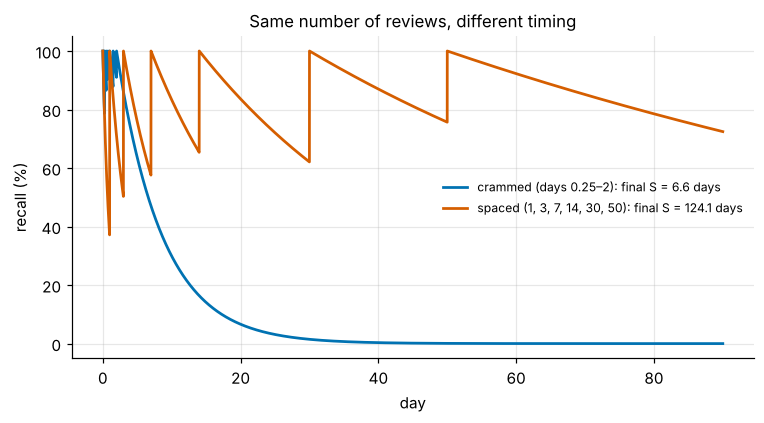

In [3]:
def simulate(review_days, horizon=90, s0=1.0, k=3.0, dt=0.01):
    t = np.arange(0, horizon, dt)
    S, last, recall, reviews = s0, 0.0, [], sorted(review_days)
    i = 0
    for ti in t:
        while i < len(reviews) and reviews[i] <= ti:
            R = math.exp(-(reviews[i] - last) / S)
            S, last = S * (1 + k * (1 - R)), reviews[i]
            i += 1
        recall.append(math.exp(-(ti - last) / S))
    return t, np.array(recall), S

schedules = {"crammed (days 0.25–2)": [0.25, 0.5, 0.75, 1.0, 1.5, 2.0],
             "spaced (1, 3, 7, 14, 30, 50)": [1, 3, 7, 14, 30, 50]}
plt.figure(figsize=(8, 3.8))
for name, days in schedules.items():
    t, r, S = simulate(days)
    plt.plot(t, 100 * r, label=f"{name}: final S = {S:.1f} days")
    r60 = 100 * r[np.searchsorted(t, 60)]
    print(f"{name:<30} recall at day 60 = {r60:.4g} %")
plt.xlabel("day"); plt.ylabel("recall (%)"); plt.legend(fontsize=8)
plt.title("Same number of reviews, different timing"); plt.show()

## Part 3 — Create your error log

This writes a template to `~/my-error-log.md`. It does not overwrite an existing file. Set `ERROR_LOG_PATH` to choose another location.

In [4]:
template = '''# My error log

| Date | Problem | What I did | What was wrong | Category | Fix / rule |
|---|---|---|---|---|---|
'''
path = Path(os.environ.get("ERROR_LOG_PATH", Path.home() / "my-error-log.md"))
if os.environ.get("CI"):
    print("CI run: not writing a file.")
elif path.exists():
    print(f"{path} already exists; leaving it unchanged.")
else:
    path.write_text(template)
    print(f"Created {path}")

CI run: not writing a file.
